<a href="https://colab.research.google.com/github/YazGonzalezHerrera/Simulaci-n-II/blob/main/Modelo%20SIR%20con%20PyMC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Modelo SIR: Ajuste de parámetros con PyMC**

El articulo de investigación *The inverse problem of a dynamical system solved with genetic algorithms* (2021), presenta el siguiente problema:

En enero de 1978, tras las vacaciones de invierno, 763 estudiantes varones regresaron a su internado. Después de una semana, uno de los estudiantes contrajo gripe, luego dos más se enfermaron y así sucesivamente. Para finales de mes, casi la mitad de los estudiantes estaba enferma, la mayor parte de la escuela se había visto afectada y a mediados de febrero la epidemia habia terminado.

**Modelo SIR**

El modelo SIR consiste en un sistema de tres ecuaciones diferenciales ordinarias no lineales acopladas que no poseen una solución analítica explícita.

En este modelo, desarrollado por Ronald Ross, William Hamer y otros, una población se divide en 3 grupos:

1. Susceptibles, $S=S(t)$
2. Infectados, $I=I(t)$
3. Recuperados, $R=R(t)$

Las ecuaciones dinámicas son las siguientes:

$\frac{dS}{dt} =  - aSI$

$\frac{dI}{dt} = aSI - bI$

$\frac{dR}{dt} = bI$

Donde $a$ es la tasa de transmisión y $b$ es la tasa promedio de recuperación.

En cualquier momento, la población total es $N=S+I+R$ y permanece constante, donde el punto superior implica derivada con respecto al tiempo $t$.

**Graficando los datos del problema**

Día,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
Infectados observados,1,3,6,25,73,222,294,258,237,191,125,69,27,11,4


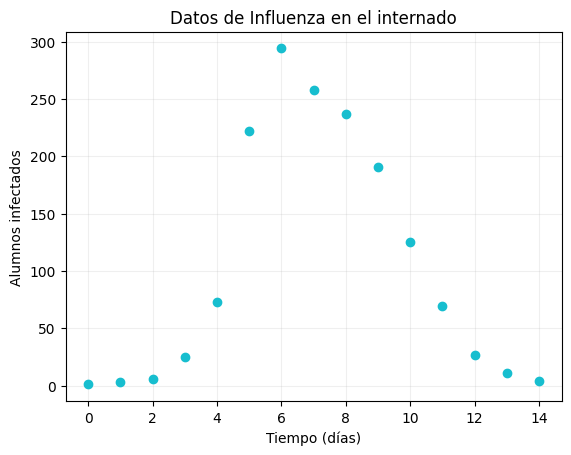

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint, solve_ivp, ODEintWarning

N = 763.0
Y0 = np.array([762.0, 1.0, 0.0])  # Compartimentos: S, I, R
t_obs = np.arange(15, dtype=float)
i_obs = np.array([1, 3, 6, 25, 73, 222, 294, 258, 237, 191, 125, 69, 27, 11, 4], dtype=float)

display(pd.DataFrame({"Día": t_obs.astype(int), "Infectados observados": i_obs.astype(int)}).T.style.hide(axis="columns"))

fig, ax = plt.subplots()
ax.scatter(t_obs, i_obs, color='C9', zorder=3)
ax.set(xlabel="Tiempo (días)", ylabel="Alumnos infectados", title="Datos de Influenza en el internado")
ax.grid(alpha=.2)
plt.show()


Al principio, $S(t)$ es aproximadamente igual a $N$ y $I(t)$ es muy pequeño. En el brote, $I(t)$ aumentará cada día hasta alcanzar un máximo y luego tenderá a disminuir lentamente como se muestra en el gráfico.

**Estadística bayesiana**

La inferencia bayesiana combina la información previa sobre los parámetros con los datos observados para obtener una distribución posterior.

Para poder llevar a cabo el modelo PyMC, expresamos el teorema de Bayes:

$p(a,b| I) = \frac{p(I| a,b) \cdot p(a,b)}{p(I)}$

Donde:

$p(a,b)$: Distribución previa o *prior*.

$p(I| a,b)$: Verosimilitud de los datos o *likelihood*.

$p(a,b| I)$: Distribución posterior o *posterior*.

$p(I)$: Constante de normalización.

Se utilizará una distribución de Poisson para representar los datos observados:

$I_{obs,t} \sim Poisson(\lambda_t)$

$\lambda_t$ se obtiene de la cantidad de infectados que predice el modelo SIR en el día $t$.

Como la distribución posterior no se obtiene directamente mediante una fórmula sencilla, se utilizará MCMC para generar muestras que permiten aproximarla.

**Modelo PyMC**

Definimos los parámetros desconocidos, se calcula la evolución de la influenza y se comparan las predicciones con los datos reales.

In [13]:
import pymc as pm
import pytensor
import pytensor.tensor as pt

# Paso de tiempo: una décima de día
dt = 0.1
pasos_por_dia = 10
n_pasos = 14 * pasos_por_dia

# Condiciones iniciales extraídas de Y0
S0, I0, R0 = Y0

# Datos observados reales
I_datos = i_obs

with pm.Model() as modelo_sir:

    # Distribuciones previas de los parámetros
    a = pm.LogNormal(
        "a",
        mu=np.log(0.002),
        sigma=0.25
    )

    b = pm.LogNormal(
        "b",
        mu=np.log(0.43),
        sigma=0.25
    )

    # Definir el paso del modelo SIR
    def paso_sir(indice, S_ant, I_ant, R_ant, a, b):

        contagios = a * S_ant * I_ant * dt
        recuperaciones = b * I_ant * dt

        S_nuevo = S_ant - contagios
        I_nuevo = I_ant + contagios - recuperaciones
        R_nuevo = R_ant + recuperaciones

        return S_nuevo, I_nuevo, R_nuevo

    # Repetir las ecuaciones a lo largo del tiempo
    estados, actualizaciones = pytensor.scan(
        fn=paso_sir,
        sequences=[pt.arange(n_pasos)],
        outputs_info=[
            pt.as_tensor_variable(float(S0), dtype="float64"),
            pt.as_tensor_variable(float(I0), dtype="float64"),
            pt.as_tensor_variable(float(R0), dtype="float64")
        ],
        non_sequences=[a, b]
    )

    S_pasos, I_pasos, R_pasos = estados

    # Condiciones iniciales
    S_todos = pt.concatenate([
        pt.as_tensor_variable([float(S0)], dtype="float64"), S_pasos
    ])

    I_todos = pt.concatenate([
        pt.as_tensor_variable([float(I0)], dtype="float64"), I_pasos
    ])

    R_todos = pt.concatenate([
        pt.as_tensor_variable([float(R0)], dtype="float64"), R_pasos
    ])

    # Extraer los resultados de cada día
    indices_diarios = np.arange(
        0, n_pasos + 1, pasos_por_dia
    )

    I_diario = I_todos[indices_diarios]

    # Definir la media de los conteos observados
    media_infectados = pm.Deterministic(
        "media_infectados",
        pt.maximum(I_diario, 1e-6)
    )

    # Verosimilitud Poisson
    observaciones = pm.Poisson(
        "observaciones",
        mu=media_infectados,
        observed=I_datos
    )

    # Muestreo de la distribución posterior
    idata = pm.sample(
        draws=1500,
        tune=1500,
        chains=4,
        cores=2,
        target_accept=0.9,
        random_seed=123
    )

/tmp/ipykernel_5476/3508351497.py:44: DeprecationWarning: Scan return signature will change. Updates dict will not be returned, only the first argument. Pass `return_updates=False` to conform to the new API and avoid this warning
  estados, actualizaciones = pytensor.scan(


Output()

Ajustar los parámetros $a$ y $b$ de manera probabilística mediante el muestreo MCMC.

In [15]:
import arviz as az

resumen = az.summary(
    idata,
    var_names=["a", "b"],
    hdi_prob=0.95,
    round_to=6
)

display(resumen)

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
a,0.002274,0.000021,0.002234,0.002313,0.000000,0.000000,4964.113781,3912.499311,1.000351
b,0.482189,0.011068,0.459156,0.502226,0.000157,0.000132,4982.239982,3925.296116,1.000849


**Gráficamos las distribuciones posteriores**

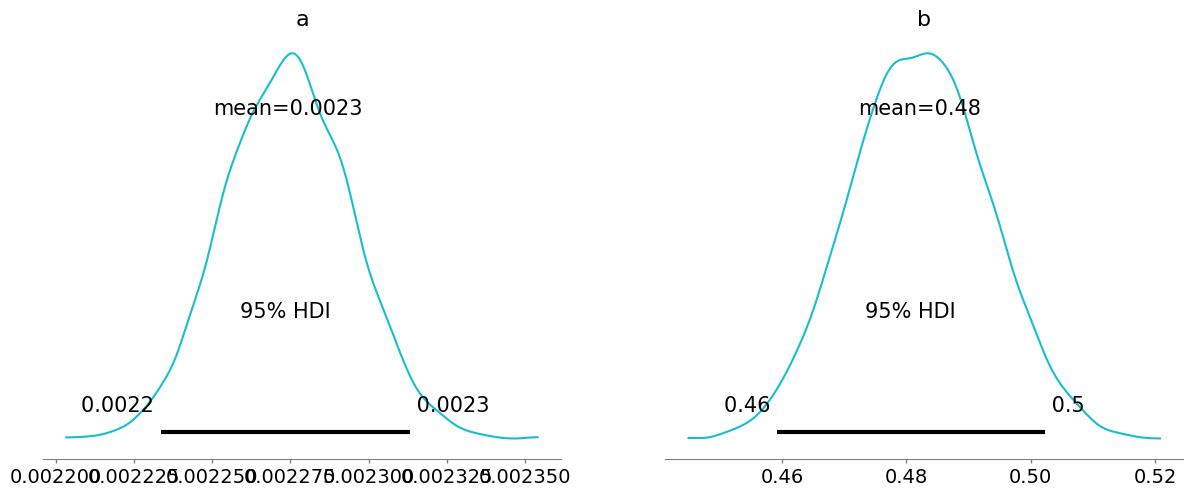

In [17]:
az.plot_posterior(
    idata,
    color="C9",
    var_names=["a", "b"],
    hdi_prob=0.95
)

plt.show()

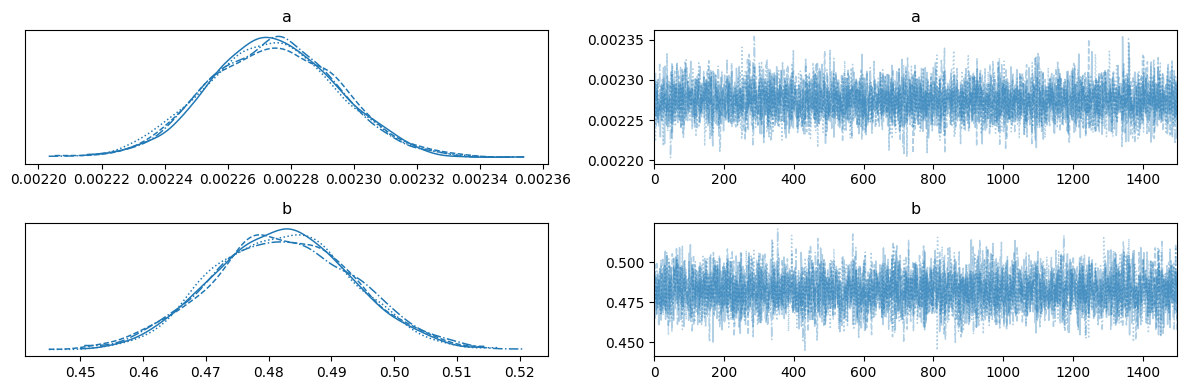

In [18]:
az.plot_trace(
    idata,
    var_names=["a", "b"]
)

plt.tight_layout()
plt.show()

Las curvas muestran el cambio de las muestras a lo largo de las iteraciones en el tiempo. Podemos ver como las cadenas oscilan alrededor de una región estable.




In [26]:
# Calcular las medias posteriores de los parámetros
a_estimado = float(idata.posterior["a"].mean().values)
b_estimado = float(idata.posterior["b"].mean().values)

# Simular el SIR con los parámetros estimados
def simular_sir(a, b, dt=0.01):
    S, I, R = float(S0), float(I0), float(R0)

    tiempos = [0.0]
    infectados = [I]

    for k in range(int(14 / dt)):
        contagios = a * S * I * dt
        recuperaciones = b * I * dt

        S -= contagios
        I += contagios - recuperaciones
        R += recuperaciones

        tiempos.append((k + 1) * dt)
        infectados.append(I)

    return np.array(tiempos), np.array(infectados)

tiempos, I_sim = simular_sir(a_estimado, b_estimado)

print(f"Estimación de a: {a_estimado:.6f}")
print(f"Estimación de b: {b_estimado:.6f}")

Estimación de a: 0.002274
Estimación de b: 0.482189


Con los parámetros estimados posteriores, mediante el ajuste bayesiano podemos obtener la gráfica de la estimación y los datos reales para visualizar la aproximación.

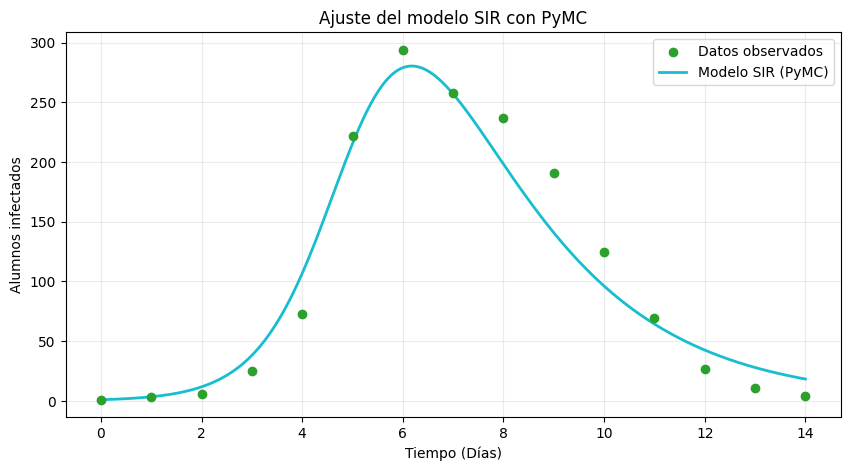

In [28]:
# Gráfica
plt.figure(figsize=(10, 5))

plt.scatter(
    t_obs, I_datos,
    color="C2",
    label="Datos observados",
    zorder=3
)

plt.plot(
    tiempos, I_sim,
    color="C9",
    linewidth=2,
    label="Modelo SIR (PyMC)"
)

plt.title("Ajuste del modelo SIR con PyMC")
plt.xlabel("Tiempo (Días)")
plt.ylabel("Alumnos infectados")
plt.grid(alpha=0.25)
plt.legend()
plt.show()


**Evolución del modelo SIR**

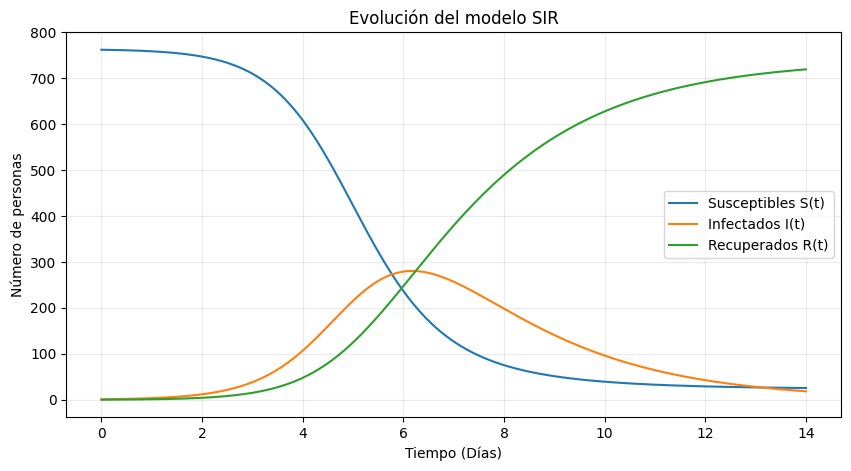

In [31]:
def simular_compartimentos(a, b, dt=0.01):
    S, I, R = float(S0), float(I0), float(R0)

    tiempos = [0.0]
    susceptibles = [S]
    infectados = [I]
    recuperados = [R]

    for k in range(int(14 / dt)):
        contagios = a * S * I * dt
        recuperaciones = b * I * dt

        S -= contagios
        I += contagios - recuperaciones
        R += recuperaciones

        tiempos.append((k + 1) * dt)
        susceptibles.append(S)
        infectados.append(I)
        recuperados.append(R)

    return tiempos, susceptibles, infectados, recuperados

t, S_sim, I_sim, R_sim = simular_compartimentos(
    a_estimado, b_estimado
)

plt.figure(figsize=(10, 5))
plt.plot(t, S_sim, label="Susceptibles S(t)")
plt.plot(t, I_sim, label="Infectados I(t)")
plt.plot(t, R_sim, label="Recuperados R(t)")

plt.title("Evolución del modelo SIR")
plt.xlabel("Tiempo (Días)")
plt.ylabel("Número de personas")
plt.grid(alpha=0.25)
plt.legend()
plt.show()

Ahora, el gráfico anterior muestra el comportamiento de los alumnos infectados, los susceptibles y los recuperados a lo largo de los dias.

Podemos ver como los infectados primero van en aumento, llega a un máximo y comienza a disminuir.

Con respecto a los susceptibles y los recuperados, son gráficas contrarias, mientras más gente se recupera, menos susceptibles son al contagio y viceversa.

**Conclusión**

Mientras que el artículo original aborda la optimización mediante algoritmos genéticos, la implementación de PyMC (empleando cadenas de Markov Monte Carlo) aporta un valor estadístico superior. El enfoque bayesiano no se limita a arrojar un único valor puntual para los parámetros, sino que entrega distribuciones posteriores completas.

Esto permite cuantificar de forma rigurosa la incertidumbre tanto en las tasas del modelo como el ruido de las observaciones.